### Exploratory Data Analysis (EDA)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
df = pd.read_csv('../data/processed/df_clean.csv', parse_dates=['Date Local'])
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (70922, 27)


,station,State,City,Date Local,State Code,County Code,Site Num,NO2 Mean,NO2 1st Max Value,NO2 1st Max Hour,...,SO2 1st Max Hour,SO2 AQI,CO Mean,CO 1st Max Value,CO 1st Max Hour,CO AQI,Year,Month,Season,Region
0,11_1_41,District Of Columbia,Washington,2010-01-01,11,1,41,19.208333,30.0,4,...,14,7,0.962939,1.25,6,14.0,2010,1,Winter,South
1,11_1_41,District Of Columbia,Washington,2010-01-02,11,1,41,8.708333,10.0,0,...,7,6,0.772917,0.80,6,9.0,2010,1,Winter,South
2,11_1_41,District Of Columbia,Washington,2010-01-03,11,1,41,7.291667,10.0,17,...,14,6,0.827083,0.90,18,10.0,2010,1,Winter,South
3,11_1_41,District Of Columbia,Washington,2010-01-04,11,1,41,13.041667,22.0,8,...,22,9,0.906250,0.95,4,10.0,2010,1,Winter,South
4,11_1_41,District Of Columbia,Washington,2010-01-05,11,1,41,15.173913,22.0,7,...,5,11,0.925947,1.00,14,11.0,2010,1,Winter,South


## EDA

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

BLUES = ['#08306b', '#2171b5', '#6baed6', '#c6dbef']  
MAIN = '#2171b5'

sns.set_theme(style='whitegrid')
sns.set_palette(BLUES)
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=BLUES)
plt.rcParams['figure.figsize'] = (9, 5)

In [4]:
pollutants = ['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']

print(df[pollutants].agg(['mean', 'median', 'std', 'min', 'max']).round(2))
print(df[pollutants].mode().iloc[0])

        O3 AQI  NO2 AQI  SO2 AQI  CO AQI
mean     35.38    22.04     3.65    4.69
median   33.00    21.00     1.00    3.00
std      16.76    13.15     6.84    3.75
min       0.00     0.00     0.00    0.00
max     200.00   111.00   118.00   67.00
O3 AQI     31.0
NO2 AQI     8.0
SO2 AQI     0.0
CO AQI      2.0
Name: 0, dtype: float64


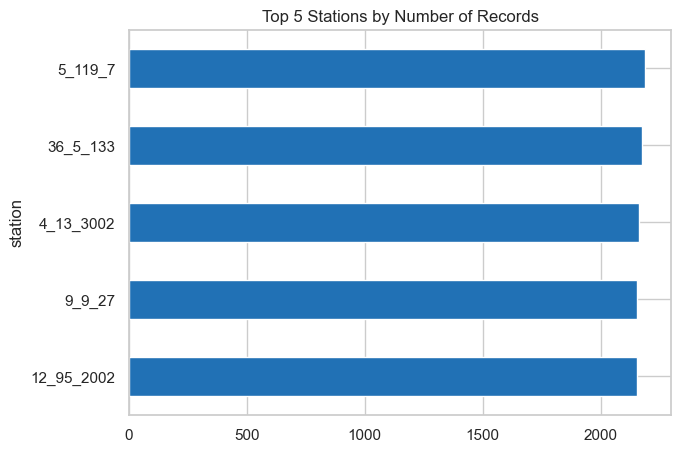

In [5]:
df.groupby('station').size().nlargest(5).sort_values().plot(
    kind='barh',
    color=MAIN,
    figsize=(7, 5),
    title='Top 5 Stations by Number of Records'
)
plt.show()

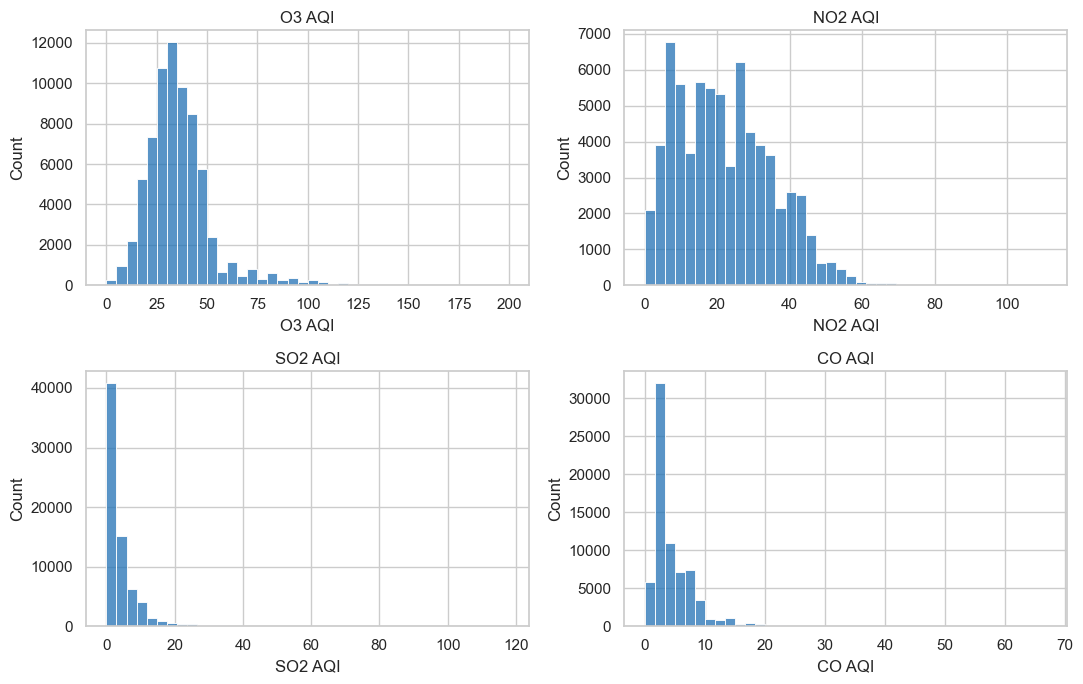

In [6]:
pol = ['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, p in zip(axes.ravel(), pol):
    sns.histplot(df[p], bins=40, color=MAIN, ax=ax)
    ax.set_title(p)
plt.tight_layout(); plt.show()

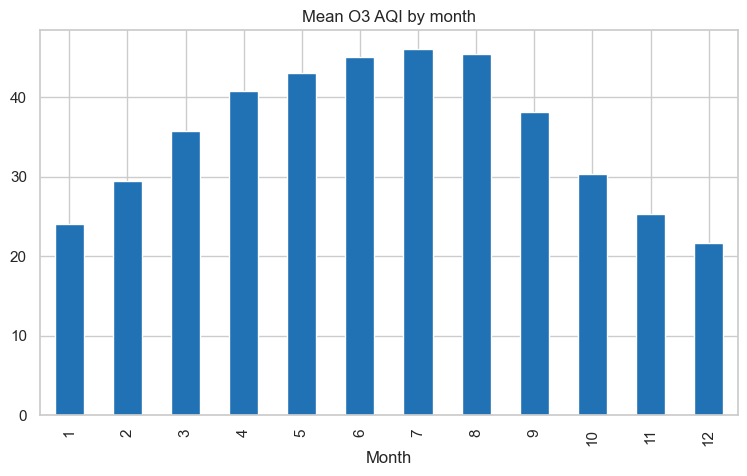

In [7]:
df.groupby('Month')['O3 AQI'].mean().plot(kind='bar', color=MAIN,
                                          title='Mean O3 AQI by month')
plt.show()

### Conclusions: Descriptive Statistics

- **O3 has the highest average AQI** (mean 35.4), but most days are below 50 (Good air quality).
- **All pollutants are right-skewed:** the mean is higher than the median, caused by a few days with very high values (spikes).
- **SO2 is the most skewed:** median = 1 and mode = 0, but max = 118. Median is a better summary than mean for SO2.
- **Maximum values:** O3 AQI reaches 200 (Unhealthy), NO2 111, SO2 118, CO 67.
- **Implication:** Use median or log scale when visualizing SO2, and do not remove the high values because they are real pollution events.

### Conclusions: Pollutant Distributions

- **What we did:** Plotted histograms for O3, NO2, SO2, and CO AQI.
- **Key finding:** All four distributions are right-skewed, confirming the mean > median pattern. SO2 and CO are concentrated near zero with a long tail.
- **Why it matters:** Skewed data needs median or log scale in visualizations, and the high values are real pollution events, not errors.

In [8]:
print(df['State'].value_counts())

State
New York                4227
California              4121
Connecticut             3991
Maine                   3891
Texas                   3846
Arizona                 3813
Pennsylvania            3500
Oklahoma                3497
Arkansas                2190
Florida                 2156
Louisiana               2125
North Carolina          2087
Massachusetts           2084
Maryland                2057
Oregon                  2043
Kansas                  2030
North Dakota            1960
Illinois                1955
Iowa                    1949
Colorado                1876
Georgia                 1868
Ohio                    1803
New Mexico              1787
New Jersey              1787
Nevada                  1735
South Dakota            1728
Wyoming                 1690
Utah                    1620
District Of Columbia    1506
Name: count, dtype: int64


In [9]:
print(df['City'].value_counts())


City
Not in a city        5518
New York             4227
Portland             3857
Phoenix              3813
North Little Rock    2190
Winter Park          2156
New Haven            2156
Baton Rouge          2125
Dallas               2113
Bethel Island        2095
Charlotte            2087
Boston               2084
Presque Isle         2077
Essex                2057
Kansas City          2030
Calexico             2026
Tulsa                1991
East Saint Louis     1955
Davenport            1949
Charleroi            1886
Welby                1876
Cornwall             1835
Cleveland            1803
Albuquerque          1787
Newark               1787
Reno                 1735
El Paso              1733
Sioux Falls          1728
Salt Lake City       1620
Philadelphia         1614
Oklahoma City        1506
Washington           1506
Name: count, dtype: int64


In [10]:
 
print(df['station'].value_counts())

station
5_119_7        2190
36_5_133       2176
4_13_3002      2164
12_95_2002     2156
9_9_27         2156
22_33_9        2125
48_113_69      2113
6_13_1002      2095
37_119_41      2087
25_25_42       2084
23_3_1100      2077
24_5_3001      2057
36_81_124      2051
41_51_80       2043
20_209_21      2030
6_25_5         2026
40_143_1127    1991
38_17_1004     1960
17_163_10      1955
19_163_15      1949
42_125_5       1886
8_1_3001       1876
13_89_2        1868
9_5_5          1835
23_5_29        1814
39_35_60       1803
35_1_23        1787
34_13_3        1787
32_31_16       1735
48_141_37      1733
46_99_8        1728
56_21_100      1690
4_13_9997      1649
49_35_3006     1620
42_101_4       1614
40_109_1037    1506
11_1_41        1506
Name: count, dtype: int64


### Conclusions: Records per State, City, and Station

- **Coverage:** The sample has 70,922 records from 29 states, 32 cities, and 37 stations.
- **States:** New York (4,227), California (4,121), and Connecticut (3,991) have the most records. District of Columbia (1,506) has the fewest. The difference comes from the number of stations per state and not from data quality.
- **Cities:** "Not in a city" has 5,518 records (3 stations), so it is not a real city. It is the closest proxy for rural areas, and it should be handled separately in the Urban vs Rural analysis.
- **Stations:** Every station has between 1,506 and 2,190 daily records (about 69% to 100% of the 2,191 days in 2010-2015). No station is dominated by a few records, so station-level comparisons are reasonable.
- **Balance:** Records are fairly evenly spread, with no single state dominating the sample.
- **Implication:** When comparing states or regions, use averages (mean/median) and not totals, because the number of stations per state is different.

In [11]:
miss = df.isna().sum()
print(miss[miss > 0])
print("Number of NaN:", df.isna().sum().sum())

CO AQI    43
dtype: int64
Number of NaN: 43


In [12]:
d = df.sort_values(['station', 'Date Local']).copy()
d['gap'] = d.groupby('station')['Date Local'].diff().dt.days - 1
gaps = d[d['gap'] > 0]

print("Num of gaps : ", len(gaps))
print("Num of missing days : ", int(gaps['gap'].sum()))

print(gaps.groupby('station')['gap'].sum().sort_values(ascending=False).head(10))

Num of gaps :  635
Num of missing days :  4589
station
4_13_9997      478.0
23_5_29        377.0
8_1_3001       315.0
38_17_1004     231.0
17_163_10      225.0
42_125_5       216.0
49_35_3006     206.0
40_143_1127    200.0
6_25_5         165.0
20_209_21      161.0
Name: gap, dtype: float64


In [13]:
print(gaps.groupby(gaps['Date Local'].dt.year)['gap'].sum())

Date Local
2010     548.0
2011    1012.0
2012     653.0
2013     753.0
2014     951.0
2015     672.0
Name: gap, dtype: float64


In [14]:
print(gaps[gaps['gap'] > 30][['station', 'Date Local', 'gap']])

           station Date Local    gap
6209     17_163_10 2012-03-02   42.0
7685     19_163_15 2011-01-03   63.0
10635    20_209_21 2013-08-09   31.0
13827    23_3_1100 2010-10-08   38.0
16869      23_5_29 2014-04-03  315.0
21298     25_25_42 2015-02-05   78.0
29620    36_81_124 2011-09-29  107.0
31888    37_119_41 2012-03-14   54.0
34472   38_17_1004 2013-09-20   94.0
38607  40_143_1127 2010-05-12   36.0
40037  40_143_1127 2014-08-27   40.0
44375     42_125_5 2011-02-28  119.0
47761      46_99_8 2015-12-18   34.0
53185   49_35_3006 2015-10-01   76.0
53210   49_35_3006 2015-12-01   36.0
55768    4_13_9997 2011-04-22   37.0
55796    4_13_9997 2011-10-14  147.0
56155    4_13_9997 2013-01-25   42.0
56312    4_13_9997 2013-09-20   31.0
58377    56_21_100 2014-12-15   83.0
62152    6_13_1002 2013-08-01   85.0
65189     8_1_3001 2010-08-17   63.0
65191     8_1_3001 2010-09-21   33.0


### Conclusions: Missing Dates (Gaps)

- **What we did:** Counted missing calendar days per station (gaps between consecutive records) and grouped them by station and year.
- **Key finding:** The sample has 635 gaps with 4,589 missing days in total (about 6% of the expected station-days). There are no NaN values in the data itself, because the missing days do not exist as rows.
- **By station:** The top 10 stations account for about 65% of missing days. Station 4_13_9997 has the most (478 days) and station 23_5_29 has the longest single gap (316 days).
- **By year:** 2011 (1,012 days) and 2014 (951 days) have the most missing days. There is no clear trend, which suggests random equipment or maintenance outages.
- **Why it matters:** Gaps are spread across many stations, so no station needs to be removed. They are handled later in the ML preprocessing (calendar completion and past-only forward filling for short gaps) and not in df_clean.

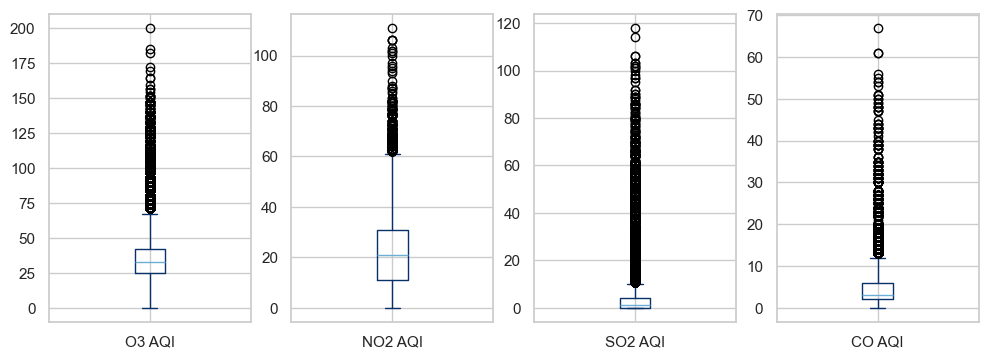

In [15]:
import seaborn as sns
aqi_cols = ['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']
df[aqi_cols].plot(kind='box', subplots=True, layout=(1, 4), figsize=(12, 4))
plt.show()

In [16]:
q1, q3 = df['O3 AQI'].quantile([0.25, 0.75])
out = df[df['O3 AQI'] > q3 + 1.5 * (q3 - q1)]
print(out['Season'].value_counts())

Season
Summer    2198
Spring     703
Fall       375
Winter       1
Name: count, dtype: int64


In [17]:
d = df.sort_values(['station', 'Date Local']).copy()
g = d.groupby('station')['O3 AQI']
d['prev'] = g.shift(1)
d['next'] = g.shift(-1)

spikes = d[d['O3 AQI'] > q3 + 1.5 * (q3 - q1)]
isolated = spikes[(spikes['prev'] < q3) & (spikes['next'] < q3)]
print(len(spikes), len(isolated))

3277 76


In [18]:
daily = out.groupby(['State', 'Date Local']).size()
print(daily.sort_values(ascending=False).head(10))

State        Date Local
Arizona      2010-05-09    2
Oklahoma     2014-04-10    2
             2014-05-05    2
             2014-06-11    2
Connecticut  2014-07-12    2
             2014-07-08    2
             2014-07-07    2
             2014-06-17    2
             2014-06-03    2
             2014-05-27    2
dtype: int64


### Conclusions: Outliers (Real vs Errors)

- **What we did:** Used the IQR rule to detect O3 AQI outliers, then checked whether they are real using value range, seasonality, neighboring days, and multiple stations on the same day.
- **Key finding:** All values are within the valid AQI range. 3,277 O3 outliers (4.6% of records) were found, 67% in Summer and only 1 in Winter, which matches the known ozone pattern.
- **Neighbors:** Only 76 spikes (2.3%) are isolated (normal values the day before and after). The other 97.7% are part of multi-day events, which is typical of real pollution episodes.
- **Multiple stations:** The days with the most spikes show two stations in the same state on the same day (e.g., Texas in August 2013 and 2014, Arizona in August 2010), supporting regional events.
- **Decision:** No outliers were removed. The 76 isolated spikes are only suspicious, not confirmed errors, and all outliers are used in the anomaly detection step.

In [19]:
state_mean = df.groupby('State')['O3 AQI'].mean().sort_values(ascending=False)
print(state_mean.round(1))

print(df.groupby('Region')[['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']].mean().round(1))

State
Arizona                 43.8
Wyoming                 43.1
New Mexico              41.3
Oklahoma                40.9
Colorado                40.7
Utah                    40.5
Nevada                  39.9
North Carolina          39.8
Texas                   38.9
California              38.8
Maryland                36.7
Illinois                35.2
Connecticut             35.1
Arkansas                35.1
Florida                 34.9
South Dakota            34.8
Georgia                 34.7
District Of Columbia    34.6
Louisiana               34.6
Iowa                    33.0
Kansas                  32.6
Pennsylvania            31.9
New York                31.5
New Jersey              31.4
North Dakota            30.5
Ohio                    29.6
Maine                   28.4
Massachusetts           26.1
Oregon                  25.6
Name: O3 AQI, dtype: float64
           O3 AQI  NO2 AQI  SO2 AQI  CO AQI
Region                                     
Midwest      32.6     18.0      6.4 

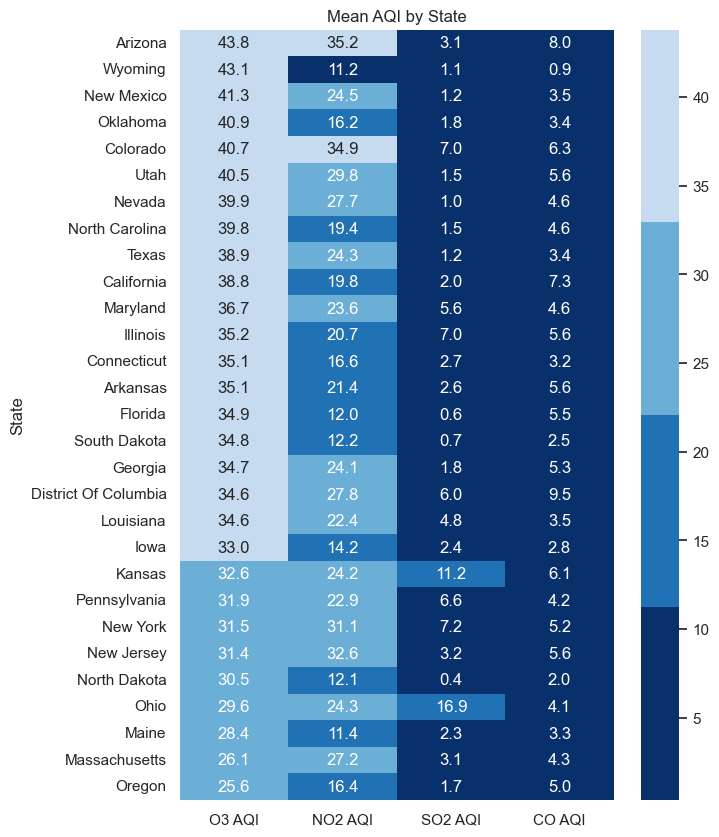

In [20]:
pol = ['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']
state_avg = df.groupby('State')[pol].mean().sort_values('O3 AQI', ascending=False)

plt.figure(figsize=(7, 10))
sns.heatmap(state_avg, annot=True, fmt='.1f', cmap=BLUES)
plt.title('Mean AQI by State')
plt.show()

In [21]:
geolocator = Nominatim(user_agent="air_quality_project")
geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)

cities = df[['State', 'City']].drop_duplicates()
cities = cities[cities['City'] != 'Not in a city']  

def get_coords(row):
    loc = geocode(f"{row['City']}, {row['State']}, USA")
    return pd.Series([loc.latitude, loc.longitude] if loc else [None, None])

cities[['lat', 'lon']] = cities.apply(get_coords, axis=1)
print(cities)
print(cities['lat'].isna().sum()) 

                      State               City        lat         lon
0      District Of Columbia         Washington  38.895098  -77.036385
1506                Florida        Winter Park  28.597771  -81.351026
5530               Illinois   East Saint Louis  38.626867  -90.159707
7485                   Iowa          Davenport  41.522469  -90.575640
9434                 Kansas        Kansas City  39.113456  -94.626497
11464             Louisiana        Baton Rouge  30.449416  -91.186966
13589                 Maine       Presque Isle  46.681222  -68.015458
15666                 Maine           Portland  43.657361  -70.258662
17480              Maryland              Essex  39.301059  -76.442487
19537         Massachusetts             Boston  42.358834  -71.057830
21621                Nevada               Reno  39.526179 -119.812658
23356            New Jersey             Newark  40.735657  -74.172367
25143            New Mexico        Albuquerque  35.084103 -106.650985
26930              N

In [22]:
manual = pd.DataFrame([
    {'State': 'Georgia',       'City': 'Not in a city', 'lat': 32.6, 'lon': -83.4},   
    {'State': 'North Dakota',  'City': 'Not in a city', 'lat': 47.0, 'lon': -100.8},
    {'State': 'Wyoming',       'City': 'Not in a city', 'lat': 41.2, 'lon': -110.0},  
])
cities_all = pd.concat([cities, manual], ignore_index=True)

In [23]:
station_avg = (df.groupby(['station', 'State', 'City'])['O3 AQI'].mean().reset_index())
station_avg = station_avg.merge(cities_all, on=['State', 'City'], how='left')
print(station_avg['lat'].isna().sum())   

0


In [24]:
fig = px.scatter_geo(station_avg.dropna(subset=['lat']),
                     lat='lat', lon='lon',
                     color='O3 AQI', size='O3 AQI',
                     hover_name='City',
                     scope='usa',
                     color_continuous_scale='Blues',
                     title='Mean O3 AQI by Station (2010-2015)')
fig.show(renderer='notebook')

### TODO: Geographic choropleth map (mean O3 AQI by state), plotly

In [25]:
us_state_abbrev = {
    'Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO','Connecticut':'CT',
    'District Of Columbia':'DC','Florida':'FL','Georgia':'GA','Illinois':'IL','Iowa':'IA',
    'Kansas':'KS','Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA',
    'Nevada':'NV','New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
    'South Dakota':'SD','Texas':'TX','Utah':'UT','Wyoming':'WY'}

In [26]:
state_avg = df.groupby('State')['O3 AQI'].mean().reset_index()
state_avg['abbr'] = state_avg['State'].map(us_state_abbrev)
print(state_avg['abbr'].isna().sum())   

fig = px.choropleth(state_avg,
                    locations='abbr',
                    locationmode='USA-states',
                    color='O3 AQI',
                    scope='usa',
                    color_continuous_scale='YlOrRd',
                    title='Mean O3 AQI by State (2010-2015)')
fig.show()

0


### Conclusions: Geographic Patterns

- **What we did:** Calculated mean AQI per state and per region.
- **O3 by state:** Highest in Arizona (43.8), Wyoming (43.1), and New Mexico (41.3). Lowest in Oregon (25.6), Massachusetts (26.1), and Maine (28.4). The gap between highest and lowest is about 18 AQI points. All state averages are below 50 (Good).
- **By region:** The West has the highest O3 (39.5), NO2 (25.3), and CO (5.7). The Midwest has the highest SO2 (6.4). The Northeast has the second highest NO2 (22.4).
- **Pattern:** Ozone is higher in the sunny, hot Southwest and lower in cooler northern and coastal states, which is consistent with ozone formation from sunlight.
- **Limitation:** Each state has only 1-3 stations, so averages represent the sampled stations and not the whole state.

In [27]:
d = df.sort_values(['station', 'Date Local']).copy()
d['gap'] = d.groupby('station')['Date Local'].diff().dt.days - 1
missing_per_station = d.groupby('station')['gap'].sum().fillna(0).sort_values()
print(missing_per_station.head(10))

station
5_119_7         1.0
36_5_133       15.0
39_35_60       23.0
40_109_1037    23.0
4_13_3002      27.0
34_13_3        28.0
42_101_4       29.0
9_9_27         35.0
12_95_2002     35.0
35_1_23        39.0
Name: gap, dtype: float64


0


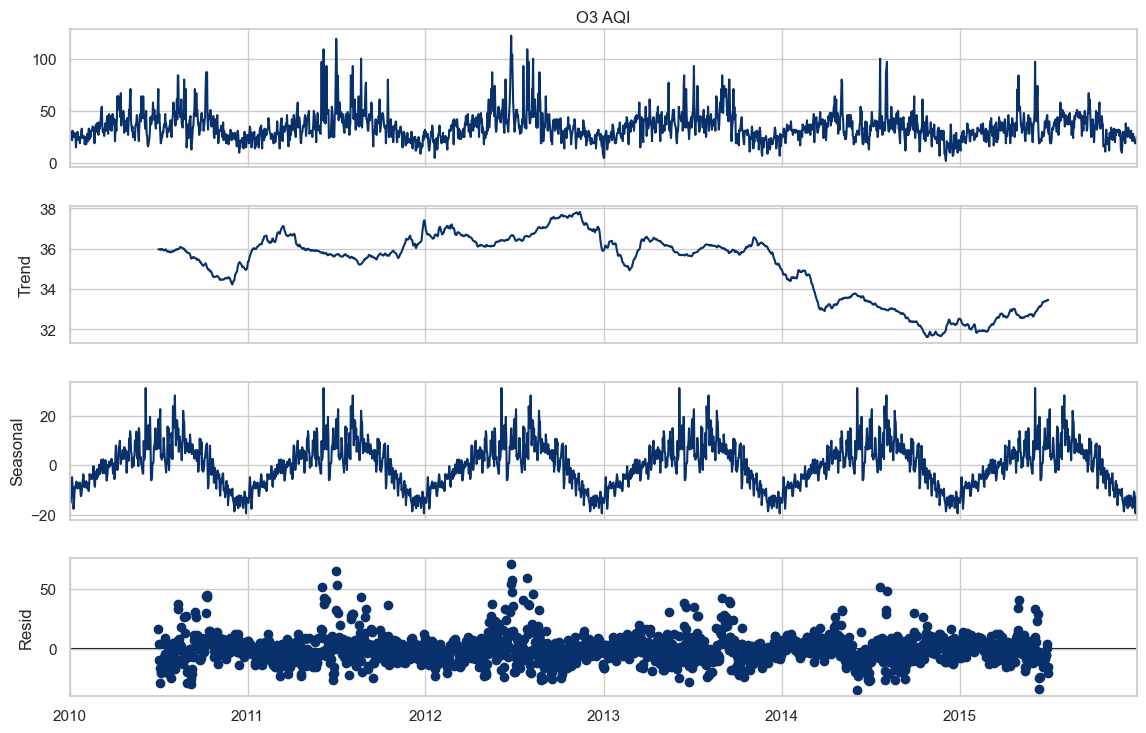

In [28]:
# EDA-only visualization: interpolation here is used only for seasonal decomposition.
# This series is not used to build ML features or the model dataset.
s = (df[df['station'] == '5_119_7']
       .set_index('Date Local')['O3 AQI']
       .asfreq('D')                    
       .interpolate(limit=7))          

print(s.isna().sum())                 

result = seasonal_decompose(s, model='additive', period=365)
result.plot()
plt.gcf().set_size_inches(12, 8)
plt.show()

### Conclusions: Time-Series Decomposition (Station 5_119_7, North Little Rock, AR)

- **What we did:** Decomposed the daily O3 AQI series (2010-2015) into trend, seasonal, and residual components using an additive model with a 365-day period. One missing day was filled by interpolation.
- **Seasonality:** Strong and regular yearly pattern. O3 peaks in summer (about +20 to +30 AQI above the average) and drops in winter (about -15 to -20). It is the dominant component, with a summer-to-winter swing of roughly 35-40 AQI points.
- **Trend:** Relatively stable between about 35 and 37 from 2010 to 2013, with a peak near late 2012 (about 38). It then declines to about 32 by late 2014 and recovers slightly to about 33.5 in 2015. The total change is small compared with the seasonal swing.
- **Residuals:** Centered around zero, mostly between -15 and +15. The largest positive residuals (50-70) occur in summers 2011 and 2012, matching the pollution spikes found earlier.
- **Limitation:** The result comes from a single station and may not represent other regions.
- **Why it matters:** Ozone is strongly seasonal, so models should include month/season features and lag features (7-day, 30-day) to capture this pattern.

         O3 AQI  NO2 AQI  SO2 AQI  CO AQI
O3 AQI     1.00     0.02    -0.04   -0.14
NO2 AQI    0.02     1.00     0.29    0.56
SO2 AQI   -0.04     0.29     1.00    0.19
CO AQI    -0.14     0.56     0.19    1.00


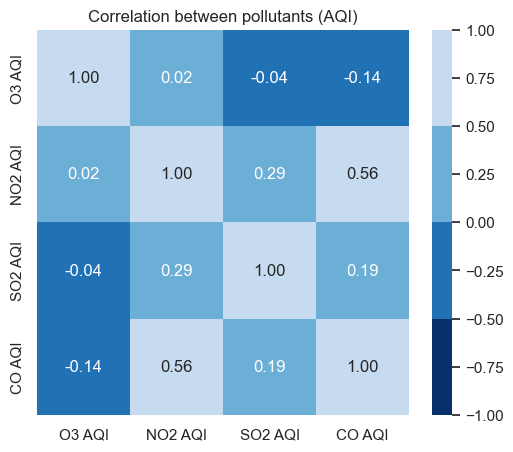

In [29]:
aqi_cols = ['O3 AQI', 'NO2 AQI', 'SO2 AQI', 'CO AQI']

corr = df[aqi_cols].corr()         
print(corr.round(2))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=BLUES, vmin=-1, vmax=1)
plt.title('Correlation between pollutants (AQI)')
plt.show()

In [30]:
corr_sp = df[aqi_cols].corr(method='spearman')
print(corr_sp.round(2))

         O3 AQI  NO2 AQI  SO2 AQI  CO AQI
O3 AQI     1.00    -0.02    -0.07   -0.14
NO2 AQI   -0.02     1.00     0.47    0.62
SO2 AQI   -0.07     0.47     1.00    0.43
CO AQI    -0.14     0.62     0.43    1.00


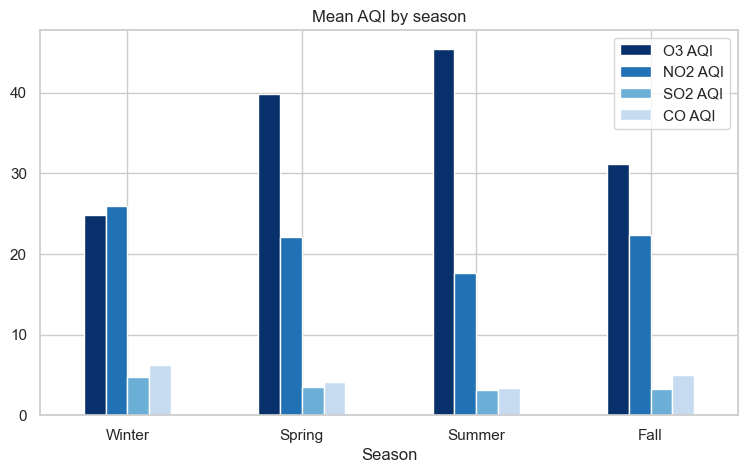

In [31]:
order = ['Winter', 'Spring', 'Summer', 'Fall']
df.groupby('Season')[pol].mean().loc[order].plot(kind='bar', color=BLUES,
                                                 title='Mean AQI by season')
plt.xticks(rotation=0); plt.show()

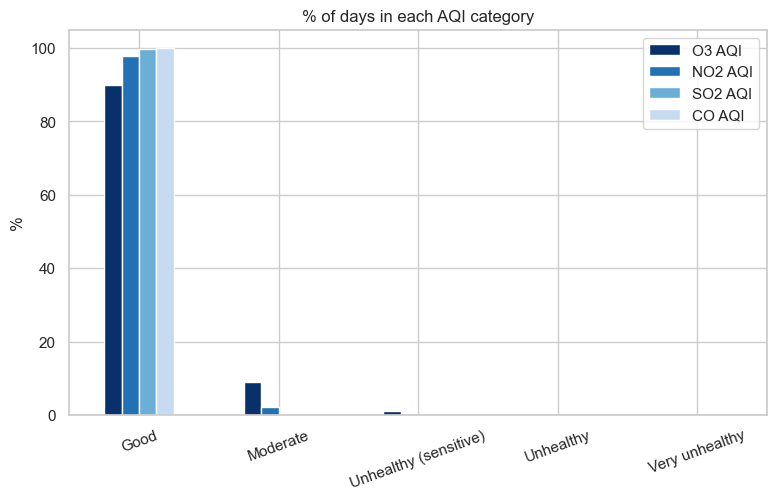

In [32]:
bins = [-1, 50, 100, 150, 200, 500]
labels = ['Good', 'Moderate', 'Unhealthy (sensitive)', 'Unhealthy', 'Very unhealthy']
cat = pd.DataFrame({p: pd.cut(df[p], bins=bins, labels=labels).value_counts(normalize=True)
                    for p in pol}).loc[labels] * 100
cat.plot(kind='bar', color=BLUES, title='% of days in each AQI category')
plt.xticks(rotation=20); plt.ylabel('%'); plt.show()

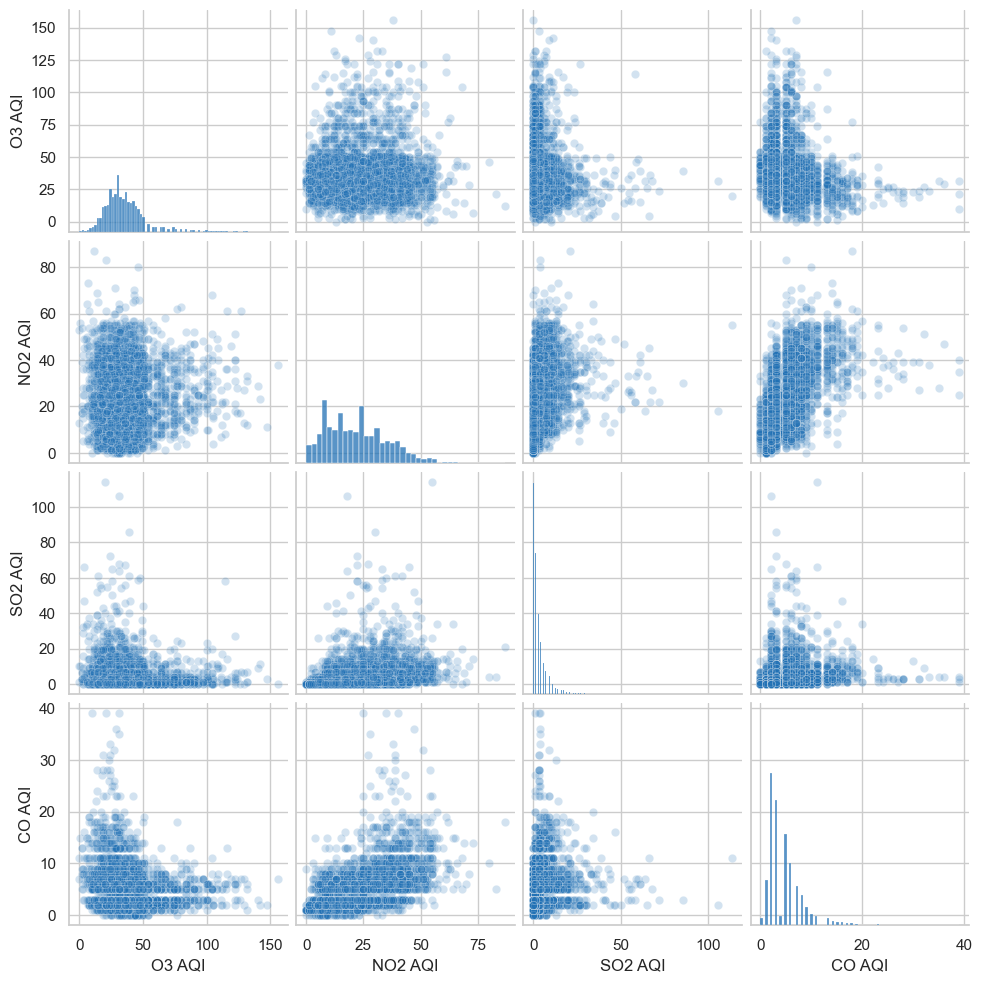

In [33]:
sns.pairplot(df[pol].sample(5000, random_state=42),
             plot_kws={'alpha': 0.2, 'color': MAIN}, diag_kws={'color': MAIN})
plt.show()

### Conclusions: Correlation Analysis (Pollutants)

- **What we did:** Computed Pearson and Spearman correlations between the AQI of O3, NO2, SO2, and CO. Spearman is preferred because the distributions are right-skewed.
- **Strongest relationship:** NO2 and CO (Pearson 0.56, Spearman 0.62), which is consistent with both coming mainly from vehicle exhaust and combustion.
- **SO2:** Moderate Spearman correlation with NO2 (0.47) and CO (0.43). Pearson is much lower (0.29 and 0.19), because SO2 is highly skewed and its spikes weaken the linear relationship.
- **O3 is almost independent:** Its correlations with the other pollutants are between -0.14 and 0.02 (strongest: CO at -0.14). Same-day levels of the other pollutants are therefore weak predictors of O3.
- **O3 vs NO2:** Near zero (0.02 Pearson, -0.02 Spearman). A possible explanation is that NO2 both consumes ozone near traffic and acts as a precursor for ozone formation in sunlight, so the effects cancel out overall. This was not tested here.
- **Limitation:** Correlations are computed on all stations pooled together and do not imply causation. Weather correlation is not included because the dataset has no temperature or wind variables.
- **Why it matters:** O3 forecasting will rely mainly on its own history (lag features), seasonality, and weather data if added, rather than on the other pollutants.

In [34]:
for s in ['Winter', 'Spring', 'Summer', 'Fall']:
    sub = df[df['Season'] == s]
    print(s, sub[aqi_cols].corr(method='spearman')['O3 AQI'].round(2).to_dict())

Winter {'O3 AQI': 1.0, 'NO2 AQI': -0.14, 'SO2 AQI': -0.23, 'CO AQI': -0.24}
Spring {'O3 AQI': 1.0, 'NO2 AQI': 0.11, 'SO2 AQI': -0.06, 'CO AQI': -0.0}
Summer {'O3 AQI': 1.0, 'NO2 AQI': 0.35, 'SO2 AQI': 0.22, 'CO AQI': 0.16}
Fall {'O3 AQI': 1.0, 'NO2 AQI': 0.1, 'SO2 AQI': -0.01, 'CO AQI': 0.01}


- **Seasonal effect:** The O3-NO2 relationship changes by season (Spearman): moderately positive in Summer (0.35), near zero in Spring (0.11) and Fall (0.10), and weakly negative in Winter (-0.14). O3 also has weak negative correlations with SO2 (-0.23) and CO (-0.24) in Winter. This explains why the pooled correlation is near zero: the positive summer and negative winter signals cancel out.
- **Implication:** Interaction features between pollutants and season (e.g., NO2 x Summer) may help the models, and correlation should not be interpreted on pooled data alone.

In [35]:
def iqr_flag(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return s > q3 + 1.5 * (q3 - q1)

df_an = df.copy()   
df_an['O3_spike'] = df_an.groupby('station')['O3 AQI'].transform(iqr_flag)

print(df_an['O3_spike'].sum())
print(df_an.groupby('station')['O3_spike'].sum().sort_values(ascending=False).head(10))
print(df_an.groupby('Year')['O3_spike'].sum())

3325
station
6_25_5         187
40_109_1037    163
48_113_69      152
4_13_3002      146
40_143_1127    140
37_119_41      134
4_13_9997      130
48_141_37      125
49_35_3006     116
9_9_27         110
Name: O3_spike, dtype: int64
Year
2010    336
2011    523
2012    747
2013    576
2014    537
2015    606
Name: O3_spike, dtype: int64


station
40_109_1037    10.8
6_25_5          9.2
4_13_9997       7.9
48_141_37       7.2
48_113_69       7.2
49_35_3006      7.2
40_143_1127     7.0
4_13_3002       6.7
37_119_41       6.4
11_1_41         5.8
Name: O3_spike, dtype: float64


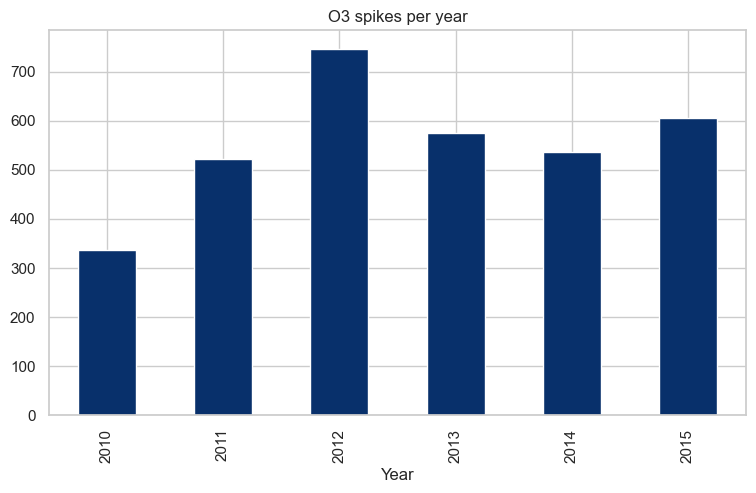

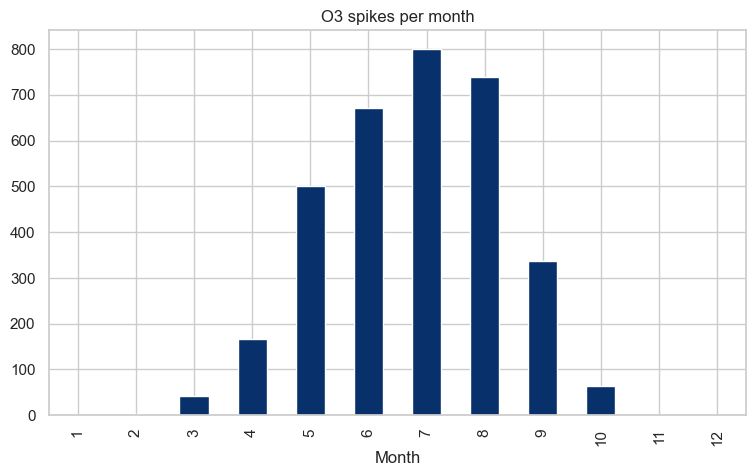

In [36]:
rate = (df_an.groupby('station')['O3_spike'].mean() * 100).sort_values(ascending=False)
print(rate.head(10).round(1))

yearly = df_an.groupby('Year')['O3_spike'].sum()
yearly.plot(kind='bar', title='O3 spikes per year')
plt.show()

df_an['Month'] = df_an['Date Local'].dt.month
df_an.groupby('Month')['O3_spike'].sum().plot(kind='bar', title='O3 spikes per month')
plt.show()

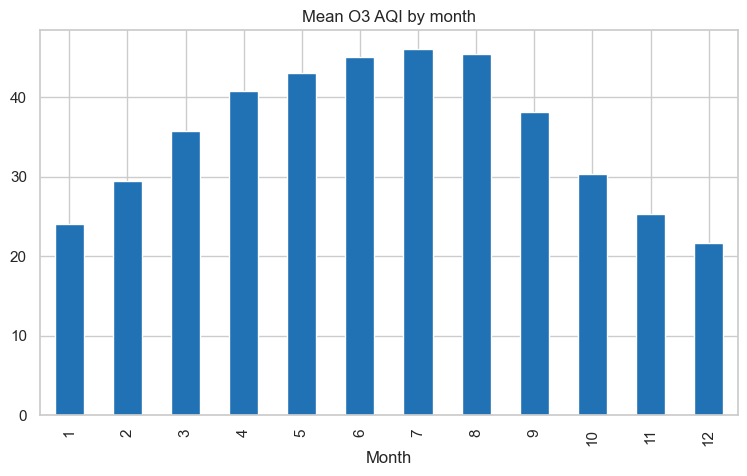

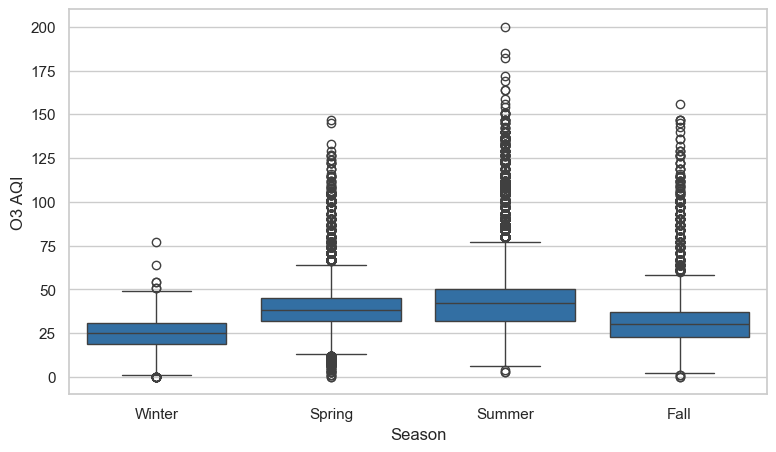

In [37]:
 
df.groupby('Month')['O3 AQI'].mean().plot(kind='bar', color=MAIN, title='Mean O3 AQI by month'); plt.show()
sns.boxplot(data=df, x='Season', y='O3 AQI', order=order, color=MAIN); plt.show()

### Conclusions: Anomaly Detection (O3 Spikes)

- **What we did:** Flagged O3 AQI spikes per station using the IQR rule (value > Q3 + 1.5 x IQR of that station), without removing any rows.
- **Key finding:** 3,325 spike days (4.7% of records), close to the pooled-threshold count (3,277), so the result is robust to the method.
- **By station (rate):** Highest spike rates are at 40_109_1037 (Oklahoma City, 10.8%), 6_25_5 (Calexico, CA, 9.2%), and 4_13_9997 (Arizona, 7.9%). Most top stations are in the South and West.
- **By year:** 2012 has the most spikes (747) and 2010 the fewest (336). 2010 also has more missing days, so part of the difference may come from data gaps.
- **By month:** July has the most spikes, while January, February, November, and December have almost none. This seasonal concentration supports that the spikes are real ozone events (sunlight and heat) and not random sensor errors.
- **Limitation:** The threshold is computed over the whole year per station, so winter values rarely exceed it. Season-specific thresholds would be needed to detect unusual days within winter.
- **Why it matters:** Spikes are the hardest part to forecast, so model evaluation should report error on spike days separately.

In [38]:
df['area_type'] = df['City'].apply(
    lambda c: 'Rural/Non-city' if c == 'Not in a city' else 'Urban')

print(df['area_type'].value_counts())
print(df.groupby('area_type')['station'].nunique())

area_type
Urban             65404
Rural/Non-city     5518
Name: count, dtype: int64
area_type
Rural/Non-city     3
Urban             34
Name: station, dtype: int64


In [39]:
print(df.groupby('area_type')[pol].agg(['mean', 'median']).round(1))

               O3 AQI        NO2 AQI        SO2 AQI        CO AQI       
                 mean median    mean median    mean median   mean median
area_type                                                               
Rural/Non-city   35.8   35.0    15.9   13.0     1.1    0.0    2.8    2.0
Urban            35.3   33.0    22.6   21.0     3.9    1.0    4.8    3.0


In [40]:
print(df.groupby(['Region', 'area_type'])[pol].mean().round(1))

                          O3 AQI  NO2 AQI  SO2 AQI  CO AQI
Region    area_type                                       
Midwest   Rural/Non-city    30.5     12.1      0.4     2.0
          Urban             33.0     19.2      7.7     4.3
Northeast Urban             31.1     22.4      4.4     4.2
South     Rural/Non-city    34.7     24.1      1.8     5.3
          Urban             37.4     20.6      2.7     4.6
West      Rural/Non-city    43.1     11.2      1.1     0.9
          Urban             39.1     26.8      2.5     6.2


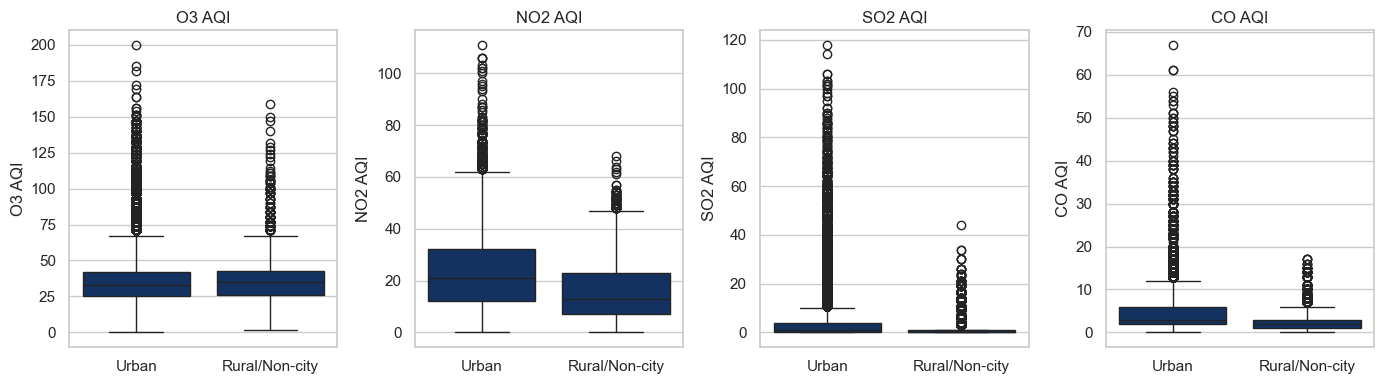

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, p in zip(axes, pol):
    sns.boxplot(data=df, x='area_type', y=p, ax=ax)
    ax.set_title(p)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

### Conclusions: Urban vs Rural Comparison

- **What we did:** Compared mean and median AQI of O3, NO2, SO2, and CO between Urban stations (34) and Rural/Non-city stations (3, a proxy for rural), overall and within each region.
- **Traffic and combustion pollutants:** NO2 (22.6 vs 15.9), SO2 (3.9 vs 1.1), and CO (4.8 vs 2.8) are higher in Urban areas on average. Within the West and Midwest, NO2 and CO are clearly lower in the Rural stations.
- **O3:** Almost the same overall (35.3 Urban vs 35.8 Rural), with no consistent direction by region: higher in Rural in the West (43.1 vs 39.1) and lower in the Midwest and South. This is consistent with ozone forming and accumulating away from emission sources, but this was not tested here.
- **Exception:** In the South, the Rural station (Georgia) has slightly higher NO2 (24.1 vs 20.6) and CO (5.3 vs 4.6) than Urban stations, so single-station results can break the pattern.
- **Limitations:** Only 3 Rural stations (one per region, none in the Northeast) versus 34 Urban, so differences may reflect station or regional effects and are indicative only. "Not in a city" is a proxy for rural and the final classification should use an external source (e.g., Census population).
- **Why it matters:** Urban/non-city type is useful for NO2, CO, and SO2 modeling, but weak for O3, which depends more on season and weather.


__________________________________________________________________________________________________________________________________________________

# Final Insights

## 1. Data Quality
- The sample has 70,922 daily records from 37 stations in 29 states (2010-2015).
- There are no NaN values, but 635 gaps (4,589 missing days, about 6% of expected station-days) exist as missing rows. They are spread across many stations, with the longest gap at 315 days (station 23_5_29).
- 3,277 O3 outliers (4.6%) were found. 97.7% of them have high neighboring days, 67% fall in summer, and only 1 in winter, so they are real pollution events and were not removed.

## 2. Distributions
- All four AQI variables are right-skewed (mean > median). SO2 is the most skewed (median 1, max 118).
- Average air quality is "Good" (below 50) for all pollutants, with O3 the highest (mean 35.4).

## 3. Geographic Patterns
- O3 is highest in the sunny Southwest (Arizona 43.8, Wyoming 43.1, New Mexico 41.3) and lowest in cooler northern and coastal states (Oregon 25.6, Massachusetts 26.1).
- The West has the highest O3, NO2, and CO. The Midwest has the highest SO2.

## 4. Time Patterns
- O3 has a strong yearly seasonality: summer peak and winter low, with a swing of about 35-40 AQI points (station 5_119_7). The trend changes only by about 6 points.
- 2012 has the most spikes (747) and July is the peak month. Winter months have almost none.

## 5. Relationships Between Pollutants
- NO2 and CO have the strongest correlation (Spearman 0.62). SO2 is moderately related to both.
- O3 is almost independent of the others overall (|r| <= 0.14), but its relationship with NO2 changes by season (0.35 in summer, -0.14 in winter).

## 6. Urban vs Rural
- NO2, SO2, and CO are higher in Urban stations. O3 is similar in both (35.3 vs 35.8).
- Only 3 non-city stations were available, so these results are indicative only.

## 7. Implications for Modeling
- Use lag features (1, 7, 30 days) and seasonal features (month, season), since O3 depends strongly on its own history and the season.
- Same-day values of other pollutants are weak predictors of O3. Weather data (temperature, wind) would likely help most and should be added if possible.
- Report model error on spike days separately, because spikes are the hardest part to forecast.
- Missing days must be handled in the ML preprocessing (calendar completion, interpolation for short gaps) before building lags.

## 8. Limitations
- Each state has only 1-3 stations, so results describe the sampled stations and not whole states.
- Urban/Rural classification is a proxy ("Not in a city"), not an official source.
- No weather data, so weather-pollution relationships were not analyzed.